In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

Part 1

In [4]:
# load data

wine = load_wine()
x, y = wine.data, wine.target

# split into train and test
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

# scale features
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# fit baseline MLP
mlp_base = MLPClassifier(random_state=42, max_iter=500)
mlp_base.fit(x_train_scaled, y_train)
print(f"Baseline Test Accuracy: {mlp_base.score(x_test_scaled, y_test):.4f}")

Baseline Test Accuracy: 0.9722


Part 2

/var/folders/pz/mv3lk6493c3d161lj9s5xqvh0000gn/T/ipykernel_3025/498650258.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_results, x='layers', y='accuracy', palette='viridis')


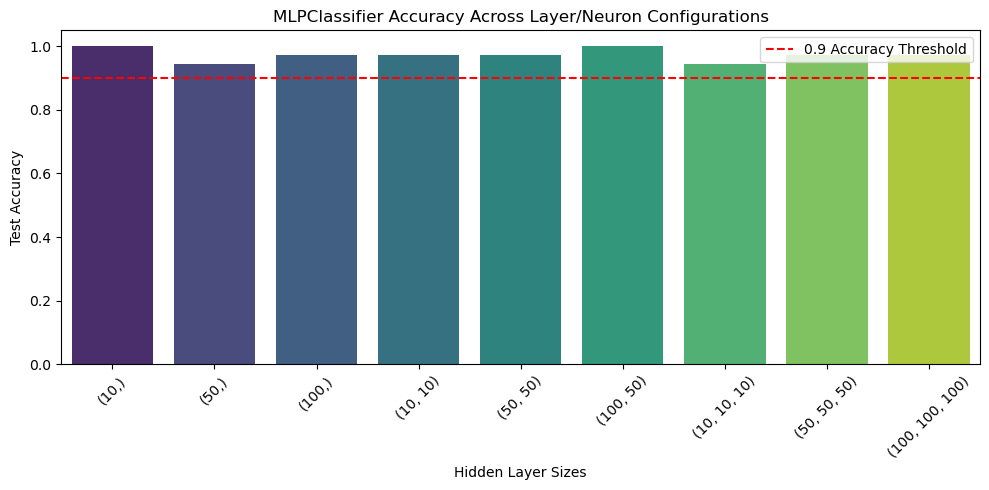

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# test a few different layer setups

layer_configs = [
    (10,),(50,),(100,),
    (10, 10), (50, 50), (100, 50),
    (10, 10, 10), (50, 50, 50), (100, 100, 100)
]

results = []
for config in layer_configs:
    mlp = MLPClassifier(hidden_layer_sizes = config, random_state = 42, max_iter=1000)
    mlp.fit(x_train_scaled, y_train)
    acc = mlp.score(x_test_scaled, y_test)
    results.append({'layers': str(config), 'accuracy': acc, 'config': config})

df_results = pd.DataFrame(results)

plt.figure(figsize=(10,5))
sns.barplot(data=df_results, x='layers', y='accuracy', palette='viridis')
plt.axhline(0.9, color='red', linestyle='--',label='0.9 Accuracy Threshold')
plt.title('MLPClassifier Accuracy Across Layer/Neuron Configurations')
plt.xlabel('Hidden Layer Sizes')
plt.ylabel('Test Accuracy')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

All of the tested model setups scored above 0.90, with perfect accuracy scored by the single later and two layer models (10,) and (100,50). Since both of these work so well, I would be most inclined to use the simplest one, the single layer configuration. This will be more computationally light while still performing well. 

The two networks that produced perfect accuracy were the (10,) and the (100,50), which both had precisions, recalls, and F1-scores of 1.00. The (100,), (10,10), (50,50), (50,50,50), and (100,100,100) networks achieved almost perfect accuracy with one misclassification, leading to an accuracy of 0.9722. The other two networks, (50,), and (10,10,10), made two errors, so they scored 0.9444. 

In [16]:
# evaluating high accuracy models
from sklearn.metrics import classification_report, confusion_matrix
high_acc_models = df_results[df_results['accuracy'] > 0.90]

for _, row in high_acc_models.iterrows():
    config = row['config']
    mlp = MLPClassifier(hidden_layer_sizes=config,random_state=42, max_iter=1000)
    mlp.fit(x_train_scaled, y_train)
    preds = mlp.predict(x_test_scaled)

    print(f"=== Architecture: {config} (Accuracy: {row['accuracy']:.4f}) ===")
    print("Confusion Matrix:\n", confusion_matrix(y_test, preds))
    print("\nClassification Report: \n", classification_report(y_test, preds, target_names=wine.target_names))
    print("-" * 50)

=== Architecture: (10,) (Accuracy: 1.0000) ===
Confusion Matrix:
 [[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]

Classification Report: 
               precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

--------------------------------------------------
=== Architecture: (50,) (Accuracy: 0.9444) ===
Confusion Matrix:
 [[12  0  0]
 [ 1 13  0]
 [ 0  1  9]]

Classification Report: 
               precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       0.93      0.93      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94     

Part 3

In [13]:
print("Unknown CSV columns:", unknown_df.columns.tolist())
print("Expected features:", wine.feature_names)

Unknown CSV columns: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']
Expected features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


In [15]:
unknown_df = pd.read_csv('../Data/unknown_wine.csv')
x_unknown = unknown_df.drop(columns=['target'])
x_unknown_scaled = scaler.transform(x_unknown)
final_model = MLPClassifier(hidden_layer_sizes=(50,), random_state=42, max_iter=1000)
final_model.fit(x_train_scaled, y_train)
probabilities = final_model.predict_proba(x_unknown_scaled)
predictions = final_model.predict(x_unknown_scaled)

prob_cols = [f"Prob_{name}" for name in wine.target_names]
results_df = pd.DataFrame(probabilities, columns=prob_cols)
results_df['Predicted_Class'] = [wine.target_names[p] for p in predictions]

print(results_df)

/opt/anaconda3/envs/default/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


     Prob_class_0  Prob_class_1  Prob_class_2 Predicted_Class
0        0.999784      0.000044      0.000172         class_0
1        0.946841      0.023744      0.029415         class_0
2        0.999783      0.000026      0.000191         class_0
3        0.997214      0.000449      0.002337         class_0
4        0.984614      0.008013      0.007373         class_0
..            ...           ...           ...             ...
173      0.000734      0.001084      0.998181         class_2
174      0.000404      0.001337      0.998259         class_2
175      0.000128      0.000502      0.999370         class_2
176      0.001329      0.004144      0.994526         class_2
177      0.001222      0.005145      0.993633         class_2

[178 rows x 4 columns]


The model gets a fairly high confidence, consistently exceeding 0.90 once the class is identified. This means that the features of the unknown samples match well with the features used in training. 